# Imports

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
import torch
import numpy as np
import pandas as pd
import tokenizers
import transformers
import tqdm.notebook as tqdm
import matplotlib.pyplot as plt

from pathlib import Path
import gc, traceback, sys

In [2]:
keras.__version__, keras.backend.backend()

('3.16.0.dev2026110603', 'torch')

In [3]:
gpus = [torch.cuda.device(i) for i in range(torch.cuda.device_count())]
if gpus:
    try:
        torch.cuda.set_per_process_memory_fraction(0.9)
        for i in range(torch.cuda.device_count()):
           print(torch.cuda.get_device_properties(i))
    except:
        print("No GPU")

_CudaDeviceProperties(name='NVIDIA GeForce RTX 3060', major=8, minor=6, total_memory=12287MB, multi_processor_count=28, uuid=9c6396a2-0e5e-4445-8ae5-e68074710ca5, pci_bus_id=1, pci_device_id=0, pci_domain_id=0, L2_cache_size=2MB)


# Choose the dataset

Get the dataset from [here](https://tatoeba.org/en/downloads). Preferably use russian to english translations.

# Tokenizer

Train your own tokenizer on a corpus for the languages you've chosen or load a pretrained tokenizer. The tokenizer must allow BOS, EOS and PAD tokens.

In [4]:
tokenizer = transformers.AutoTokenizer.from_pretrained('gpt2')

In [5]:
num_added = tokenizer.add_special_tokens({'pad_token': '<|padding|>'})
tokenizer.eos_token, tokenizer.pad_token, tokenizer.eos_token_id, tokenizer.pad_token_id, num_added

('<|endoftext|>', '<|padding|>', 50256, 50257, 1)

# Dataset

In [6]:
DATASET_PATH = Path("../dataset_lang")

In [7]:
def get_total_sentences():
    en_sentences = pd.read_csv(DATASET_PATH / "eng_sentences.tsv", sep="\t", header=None, names=["en_id", "lang", "sentence"]).drop(columns=["lang"])
    ru_sentences = pd.read_csv(DATASET_PATH / "rus_sentences.tsv", sep="\t", header=None, names=["ru_id", "lang", "sentence"]).drop(columns=["lang"])
    links = pd.read_csv(DATASET_PATH / "links.tsv", sep="\t", header=None, names=["en_id", "ru_id"])
    return (
        links
        .merge(en_sentences, on="en_id", how="inner")
        .merge(ru_sentences, on="ru_id", how="inner")
        .drop(columns=["en_id", "ru_id"])
        .rename(columns={"sentence_x": "en", "sentence_y": "ru"})
    )

In [8]:
total_sentences = get_total_sentences()
total_sentences.head()

,en,ru
0,Let's try something.,Давайте что-нибудь попробуем!
1,Let's try something.,Давайте что-нибудь попробуем.
2,Let's try something.,Давай кое-что попробуем.
3,I have to go to sleep.,Мне пора идти спать.
4,I have to go to sleep.,Мне нужно идти спать.


### Skip

In [30]:
list(zip(total_sentences.ru[:2], total_sentences.en[:2]))

[('Давайте что-нибудь попробуем!', "Let's try something."),
 ('Давайте что-нибудь попробуем.', "Let's try something."),
 ('Давай кое-что попробуем.', "Let's try something."),
 ('Мне пора идти спать.', 'I have to go to sleep.'),
 ('Мне нужно идти спать.', 'I have to go to sleep.'),
 ('Я должен ложиться спать.', 'I have to go to sleep.'),
 ('Я должна ложиться спать.', 'I have to go to sleep.'),
 ('Сегодня 18 июня, и это день рождения Мюриэл!',
  "Today is June 18th and it is Muiriel's birthday!"),
 ('Мюриэл сейчас 20.', 'Muiriel is 20 now.'),
 ('Пароль «Muiriel».', 'The password is "Muiriel".')]

In [10]:
encoded = tokenizer(list(zip(total_sentences.ru, total_sentences.en)))['input_ids']

Token indices sequence length is longer than the specified maximum sequence length for this model (1125 > 1024). Running this sequence through the model will result in indexing errors


In [11]:
lengths = np.asarray(list(map(len, encoded)))

In [12]:
lengths[np.argpartition(lengths, -10)[-10:]]

array([1020, 1064, 1065, 1072, 1090, 1093, 1113, 1114, 1116, 1125])

In [13]:
np.quantile(lengths, [0.7, 0.8, .9, .99, .999, .9999])

array([ 47.    ,  52.    ,  61.    , 105.    , 219.    , 494.0999])

''

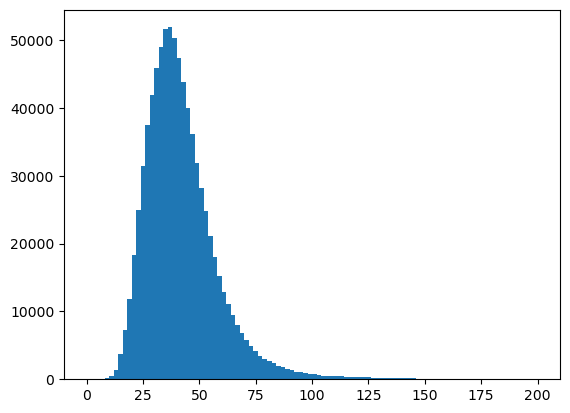

In [14]:
plt.hist(lengths, bins=100, range=(0, 200))
""

### Next

Since the dataset is rather large, you can omit the validation dataset and just use a set of test sentences after the training.

Create a dataset that returns the following
* A pair of tensors `((None, L), (None, P))` -- input sequence of tokens and output sequence of tokens to be fed into decoder (this should start with the BOS token)
* A tensor `(None, P)` -- output sequence of tokens to be predicted (this should end with EOS token)

In [184]:
class Dataset(keras.utils.PyDataset):

    def __init__(
            self,
            X: pd.Series,
            y: pd.Series,
            *,
            tokenizer,
            X_max_len: int,
            y_max_len: int,
            batch_size: int,
            seed: int | None = None, 
            shuffle: bool = False, 
            **kwargs
    ):
        super().__init__(**kwargs)
        self.shuffle = shuffle
        self.batch_size = batch_size
        self.seed = seed
        self.rng = np.random.default_rng(seed)

        self.tokenizer = tokenizer
        
        self.X = X
        self.y = y

        self.X_max_len = X_max_len
        self.y_max_len = y_max_len

        self.indexes = np.arange(len(self.X))

        self.on_epoch_end()

    def __len__(self):
        return (len(self.indexes) + self.batch_size - 1) // self.batch_size

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indexes)
    
    def __getitem__(self, index: int):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        batch = self.indexes[start:end]

        _X = self.X[batch]
        _y = self.y[batch]

        _X = self.tokenizer(
            list(zip(_X, _y)), 
            max_length=self.X_max_len + 1,
        )["input_ids"]

        _X = keras.utils.pad_sequences(_X, padding='post', truncating='post', value=self.tokenizer.pad_token_id)

        _X_pred = _X[:, 1:self.X_max_len+1]
        _X = _X[:, :self.X_max_len]
        
        _X_pred[:, -1] = np.where(_X_pred[:, -1] != self.tokenizer.pad_token_id, self.tokenizer.eos_token_id, self.tokenizer.pad_token_id)

        return _X, _X_pred

    def __getitem__(self, index: int):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        batch = self.indexes[start:end]

        _X = self.X[batch]
        _y = self.y[batch]

        bos = np.full((len(batch), 1), self.tokenizer.bos_token_id)

        _X = self.tokenizer(_X.to_list(), return_tensors='np')["input_ids"]
        _X = keras.utils.pad_sequences(_X, padding='post', value=self.tokenizer.pad_token_id)
        _X = np.concatenate([bos, _X], axis=1)
        _X = _X[:, :self.X_max_len]

        _y = self.tokenizer(_y.to_list(), return_tensors='np')["input_ids"]
        _y = keras.utils.pad_sequences(_y, padding='post', value=self.tokenizer.pad_token_id)
        _y = np.concatenate([bos, _y], axis=1)        
        
        _y_pred = _y[:, 1:self.y_max_len+1].copy()
        _y = _y[:, :self.y_max_len]

        first_pad = np.argmax(_y_pred == tokenizer.pad_token_id, axis=-1)
        
        _y_pred[np.arange(len(batch)), first_pad] = self.tokenizer.eos_token_id
        _y_pred[:, -1] = np.where(_y_pred[:, -1] != self.tokenizer.pad_token_id, self.tokenizer.eos_token_id, self.tokenizer.pad_token_id)

        diff_shape = _y.shape[-1] - _y_pred.shape[-1]
        if diff_shape > 0:
            _y_pred = np.pad(_y_pred, pad_width=((0, 0), (0, diff_shape)), constant_values=self.tokenizer.pad_token_id)

        return (_X, _y), _y_pred


In [212]:
train = Dataset(
    total_sentences.ru, total_sentences.en,
    tokenizer=tokenizer,
    X_max_len=64, y_max_len=32,
    batch_size=64, seed=42, shuffle=True
)

In [186]:
I = 1
print(train[I])
_, i = train[I]
print(*[j for j in i], sep = '\n')

((array([[50256,   140,   255, ..., 50257, 50257, 50257],
       [50256,   140,    96, ..., 50257, 50257, 50257],
       [50256,   140,    95, ..., 50257, 50257, 50257],
       ...,
       [50256,   140,   254, ..., 50257, 50257, 50257],
       [50256,   140,   253, ..., 50257, 50257, 50257],
       [50256,   140,    96, ..., 50257, 50257, 50257]], shape=(256, 128)), array([[50256,  1212,   318, ..., 50257, 50257, 50257],
       [50256,    40,   423, ..., 50257, 50257, 50257],
       [50256, 13787,  1422, ..., 50257, 50257, 50257],
       ...,
       [50256,    32,  7850, ..., 50257, 50257, 50257],
       [50256, 21321,  1566, ..., 50257, 50257, 50257],
       [50256,  1639,   423, ..., 50257, 50257, 50257]], shape=(256, 32))), array([[ 1212,   318,   616, ..., 50257, 50257, 50257],
       [   40,   423,   640, ..., 50257, 50257, 50257],
       [13787,  1422,   470, ..., 50257, 50257, 50257],
       ...,
       [   32,  7850,   318, ..., 50257, 50257, 50257],
       [21321,  1566,  943

In [187]:
texts = pd.Series([
    "Я люблю ходить в кино.",
    "Автобусы это разновидность машин.",
    "Внутри дома стоит кровать.",
    "Солнце светит на небе.",
    "Это перевод с русского на английский.",
    "Прошло 5 эпох для обучения модели.",
    
    "Меня зовут Вася.",
    "Меня зовут и я прихожу.",
    "Слушайте, а как мы будем разбираться с этой проблемой?",
    "Я хочу кушать.",
    "Я.",
    "Мы.",
    "Дом.",
    "Улица.",
    "Фонарь.",
    "Аптека.",

    "Давай кое-что попробуем.",
    "Давай кое-что попробуем!",
    "Давайте что-нибудь попробуем.",

    "Мне нужно идти спать.",
    "Мне пора идти спать.",

    "Это длинное предложение, которое не несёт в себе особого смысла, а находится здесь чтобы проверить ограничение на длину при вызове функции перевода текста.",
    "Это первое предложение с точкой. После него идёт второе предложение, отделённое от первого.",

    "Я стреляю из лука.",
    "Я чищу лук.",

    "На амбаре висит большой замок.",
    "На горах стоит большой замок.",
    "Я открыл замок на двери."
])
translations = pd.Series([
    "I like going to the cinema.",
    "Buses are a type of vehicle.",
    "There is a bed inside the house.",
    "The sun is shining in the sky.",
    "This is a translation from Russian into English.",
    "Five epochs have passed for training the model.",

    "My name is Vasya.",
    "They call me, and I come.",
    "Listen, how are we going to deal with this problem?",
    "I want to eat.",
    "I.",
    "We.",
    "House.",
    "Street.",
    "Streetlight.",
    "Pharmacy.",

    "Let's try something.",
    "Let's try something!",
    "Let's try something.",

    "I need to go to bed.",
    "It's time for me to go to bed.",

    "This is a long sentence that does not carry much special meaning and is here to test the length limit when calling the text translation function.",
    "This is the first sentence with a period. After it comes the second sentence, separated from the first.",

    "I am shooting from a bow.",
    "I am peeling an onion.",

    "A large lock hangs on the barn.",
    "A large castle stands on the mountains.",
    "I opened the lock on the door."
])

In [213]:
test = Dataset(
    texts, translations,
    tokenizer=tokenizer,
    X_max_len=64, y_max_len=32,
    batch_size=64, shuffle=False
)

In [189]:
test[0]

((array([[50256,   140,   107, ..., 50257, 50257, 50257],
         [50256,   140,   238, ..., 50257, 50257, 50257],
         [50256,   140,   240, ..., 50257, 50257, 50257],
         ...,
         [50256,   140,   251, ..., 50257, 50257, 50257],
         [50256,   140,   251, ..., 50257, 50257, 50257],
         [50256,   140,   107, ..., 50257, 50257, 50257]], shape=(28, 128)),
  array([[50256,    40,   588,  1016,   284,   262, 22041,    13, 50257,
          50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257,
          50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257,
          50257],
         [50256,    33,  2664,   389,   257,  2099,   286,  4038,    13,
          50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257,
          50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257,
          50257],
         [50256,  1858,   318,   257,  3996,  2641,   262,  2156,    13,
          50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257,

# Model

Create a model for training. The model should have two inputs: input sequence `(None, L)` and output sequence`(None, P)`. The model output is a single tensor `(None, P)` logits (or probabilities) of the next token predicted for each input one. The model MUST have decoder only architecture.

In [190]:
@keras.saving.register_keras_serializable()
class Embedding(keras.layers.Layer):

    def __init__(
        self,
        vocab_size: int,
        embedding_size: int,
        max_length: int,
        **kwargs
    ):
        super().__init__(**kwargs)
        
        self.embedding_size = embedding_size
        self.max_length = max_length
        
        self.embedding = keras.layers.Embedding(vocab_size, embedding_size)

    def build(self, input_shape):
        self.pos_embed = self.add_weight((1, self.max_length, self.embedding_size), name='pos_embed')

        super().build(input_shape)

    def call(self, x: keras.KerasTensor) -> keras.KerasTensor:
        b, l = keras.ops.shape(x)
        x = self.embedding(x)
        x = x + self.pos_embed[:, :l, :]

        return x

    def get_config(self):
        config = super().get_config()
        config.update({
            "vocab_size": self.embedding.input_dim,
            "embedding_size": self.embedding_size,
            "max_length": self.max_length,
        })
        return config

In [191]:
@keras.saving.register_keras_serializable()
class CausalPaddingMask(keras.layers.Layer):
    def __init__(
        self, 
        pad_token_id: int,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.pad_token_id = pad_token_id
        
    def call(self, inputs: tuple[keras.KerasTensor, keras.KerasTensor]):
        x, y = inputs
        concat = keras.ops.concatenate(inputs, axis=1)
        
        mask = concat != self.pad_token_id

        x_len = x.shape[-1]
        total_len = concat.shape[-1]

        i = keras.ops.arange(total_len)[:, None]
        j = keras.ops.arange(total_len)[None, :]

        q_x = i < x_len
        k_x = j < x_len
        causal_part = j <= i

        causal_mask = k_x | (~q_x & causal_part)

        return keras.ops.expand_dims(mask, 1) & causal_mask

    def get_config(self):
        config = super().get_config()
        config.update({
            "pad_token_id": self.pad_token_id,
            "add_cls": self.add_cls,
        })
        return config

In [192]:
def get_name(prefix: str | None = None, suffix: str | None = None, separator: str = '_') -> str | None:
    return prefix and prefix + separator + suffix or suffix or None

In [193]:
def get_model(
    vocab_size: int,
    embedding_size: int,
    max_length: int,
    num_blocks: int,
    num_heads: int,
    pad_token_id: int,    
    name: str | None = None,
    return_attention_scores: bool = False,
) -> keras.Model:
    '''Creates a model with Transformer architecture for binary sequence classification.

    Arguments:
        vocab_size: size of the tokenizer vocabulary
        embedding_size: size of the internal mdoel representations 
        max_length: maximal allowed sequence length for each of the input sequences
        num_blocks: number of transformer blocks
        num_heads: number of multi head attentions heads
        pad_token_id: id of the padding token
        name: the model name

    Returns:
        The model'''

    assert embedding_size % 4 == 0

    inputs_x = keras.layers.Input((None, ), dtype='int32', name="input_x")
    inputs_y = keras.layers.Input((None, ), dtype='int32', name="input_y")

    mask = CausalPaddingMask(pad_token_id=pad_token_id, name="mask")([inputs_x, inputs_y])
    
    x = keras.layers.Concatenate(name="concat", axis=1)([inputs_x, inputs_y])
    
    x = Embedding(vocab_size, embedding_size, max_length, name='embedding')(x)
    x = keras.layers.LayerNormalization(name='ln')(x)

    ff_features = embedding_size * 4
    attention_scores = []

    for i in range(num_blocks):
        block_name = f'block_{i}'

        mha = keras.layers.MultiHeadAttention(num_heads=num_heads, key_dim=embedding_size // num_heads, name=get_name(block_name, 'mha'))

        if return_attention_scores:
            y, attn = mha(x, x, attention_mask=mask, return_attention_scores=True)
            attention_scores.append(attn)
        else:
            y = mha(x, x, attention_mask=mask)
        
        x = keras.layers.Add(name=get_name(block_name, 'add1'))([x, y])
        x = keras.layers.LayerNormalization(name=get_name(block_name, 'ln1'))(x)

        y_value = keras.layers.Dense(ff_features, name=get_name(block_name, 'swiglu_value'))(x)
        y_gate  = keras.layers.Dense(ff_features, name=get_name(block_name, 'swiglu_gate'), activation='swish')(x)
        y = keras.layers.Multiply(name=get_name(block_name, 'swiglu'))([y_gate, y_value])
        y = keras.layers.Dense(embedding_size, name=get_name(block_name, 'ff'))(y)
        
        x = keras.layers.Add(name=get_name(block_name, 'add2'))([x, y])
        x = keras.layers.LayerNormalization(name=get_name(block_name, 'ln2'))(x)

    def _take_last_P(x_and_y):
        x, y = x_and_y
        T = keras.ops.shape(x)[1]   # L + P
        P = keras.ops.shape(y)[1]   # P (length of inputs_y)
        idx = keras.ops.arange(T - P, T)
        return keras.ops.take(x, idx, axis=1)

    x = keras.layers.Lambda(_take_last_P, name="select_target_positions")([x, inputs_y])

    x = keras.layers.Dense(vocab_size, name='output')(x)

    if return_attention_scores:
        outputs = {
            "logits": x,
            "attention_scores": keras.ops.stack(attention_scores),
        }
    else:
        outputs = x

    return keras.models.Model(inputs=[inputs_x, inputs_y], outputs=outputs, name=name)

# Training

Train your model using teacher forcing.

In [214]:
model = get_model(
    vocab_size=len(tokenizer.get_vocab()),
    embedding_size=128,
    max_length=64 + 32,
    num_blocks=4,
    num_heads=4,
    pad_token_id=tokenizer.pad_token_id,
    name='transformer_lang',
    return_attention_scores=False,
)

In [215]:
model.summary()

Model: "transformer_lang"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_x             │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_y             │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat              │ (None, None)      │          0 │ input_x[0][0],    │
│ (Concatenate)       │                   │            │ input_y[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 128) │  6,445,312 │ concat[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ln                  │ (None, None, 128) │        256 │ embedding[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mask                │ (None, None,      │          0 │ input_x[0][0],    │
│ (CausalPaddingMask) │ None)             │            │ input_y[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_mha         │ (None, None, 128) │     66,048 │ ln[0][0],         │
│ (MultiHeadAttentio… │                   │            │ ln[0][0],         │
│                     │                   │            │ mask[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_add1 (Add)  │ (None, None, 128) │          0 │ ln[0][0],         │
│                     │                   │            │ block_0_mha[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_ln1         │ (None, None, 128) │        256 │ block_0_add1[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_swiglu_gate │ (None, None, 512) │     66,048 │ block_0_ln1[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_swiglu_val… │ (None, None, 512) │     66,048 │ block_0_ln1[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_swiglu      │ (None, None, 512) │          0 │ block_0_swiglu_g… │
│ (Multiply)          │                   │            │ block_0_swiglu_v… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_ff (Dense)  │ (None, None, 128) │     65,664 │ block_0_swiglu[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_add2 (Add)  │ (None, None, 128) │          0 │ block_0_ln1[0][0… │
│                     │                   │            │ block_0_ff[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_ln2         │ (None, None, 128) │        256 │ block_0_add2[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_mha         │ (None, None, 128) │     66,048 │ block_0_ln2[0][0… │
│ (MultiHeadAttentio… │                   │            │ block_0_ln2[0][0… │
│                     │                   │            │ mask[0][0]        │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 13,986,130 (53.35 MB)

 Trainable params: 13,986,130 (53.35 MB)

 Non-trainable params: 0 (0.00 B)

In [216]:
EPOCHES = 5

In [217]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=keras.optimizers.AdamW(
        keras.optimizers.schedules.CosineDecay(
            initial_learning_rate=5e-4,
            decay_steps=EPOCHES * len(train),
            alpha=1e-4,
        )
    ),
    metrics=[
        'accuracy',
    ]
)

In [218]:
with torch.no_grad():
    torch.cuda.empty_cache()
torch.cuda.empty_cache()
if sys.last_traceback:
    traceback.clear_frames(sys.last_traceback)
gc.collect(), torch.cuda.memory_allocated(), torch.cuda.memory_reserved()

(10502, 720216064, 7075790848)

In [219]:
SAVE_MODEL_PATH = Path("./saved")
SAVE_MODEL_PATH.mkdir(parents=True, exist_ok=True)

In [220]:
model.fit(
    train,
    validation_data=test,
    epochs=EPOCHES,
    callbacks=[
            keras.callbacks.ModelCheckpoint(
            SAVE_MODEL_PATH / f"{model.name}.keras",
            save_best_only=True,
        ),
        keras.callbacks.CSVLogger(
            SAVE_MODEL_PATH / f"log_{model.name}.csv", 
            separator=",",
            append=True,
        ),
    ]
)

Epoch 1/5
  447/12964 ━━━━━━━━━━━━━━━━━━━━ 17:09 82ms/step - accuracy: 0.6278 - loss: 3.1329

KeyboardInterrupt: 

# Testing

Make a function for text translation. Translate some text and evaluate model performance.

In [ ]:
def translate(
    text: str,
    tokenizer: 'tokenizer',
    model: keras.Model,
    max_len: int = 20
) -> str:
    '''Predicts `text` translation using the `model`.

    Arguments:
        text: text to be translated
        tokenizer: tokenizer to use
        model: model ot use
        max_len: maximum length of the prediction (in tokens)

    Returns:
        tranlated text'''
    ...

# Bonus

Train the model using its own predictions as inputs. The probability to use the predicted tokens instead of the ones from the dataset should increase as the training progresses. Train for one or two epochs. Evaluate the model, does the model perform better?